# Optimizing AI Trading Algorithms - Course Project


In this project you will practice optimizing various aspects of a machine learning model for predicting stock price movements. This will provide you with an opportunity to integrate the concepts covered in the course, such as data preprocessing and cleaning, hyperparameter tuning, detecting and addressing over-/under-fitting, model evaluation, and feature selection techniques. While you will use real-world data in this project, the goal is not necessarily to build a "winning" trading _strategy_. The goal of this course has been to equip you with the tools, techniques, concepts and insights you need to evaluate, optimize and monitor *your own* trading strategies.


## The Scenario

You are an analyst at a boutique investment firm tasked with coming up with a novel idea for investing in specific sectors of the industry. You've heard that the Utilities, Consumer Staples and Healthcare sectors are relatively resilient to economic shocks and recessions, and that stock market investors tend to flock to these sectors in times of uncertainty. You decide to take the [SPDR Healthcase Sector ETF (NYSEARCA: XLV)](https://www.sectorspdrs.com/mainfund/XLV) and try to model its returns' dynamics using a machine learning AI strategy. Your novel idea is to get data for the volatility index [(INDEXCBOE: VIX)](https://www.cboe.com/tradable_products/vix/) as a proxy for uncertainty in the market. You also decide to take a look at [Google Trends data](https://trends.google.com/trends/explore?date=all&geo=US&q=recession) for the search term "recession" in the United States, in order to try and see if there is any meaningful relationship between the general public's level of concern about a recession happening and the price movements of the Health Care Select Sector SPDR Fund.


You decide to train a binary **classification** model that merely attempts to predict the **direction** of XLV's 5-day price movements. In other words, you want to see if on any given day, with the above data in hand, you could reliably predict whether the price of XLV will increase or decrease over the next 5 trading days.

Run the cell below to `import` all the Python packages and modules you will be using throughout the project.

In [1]:
# Packages (ta, plotly, yfinance, scikit-learn, seaborn) are installed in this environment.
# In the Udacity workspace this line installs the `ta` package:
# !pip install --upgrade pip ta --quiet

In [2]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns
import yfinance as yf
from plotly.subplots import make_subplots
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import GridSearchCV, learning_curve, train_test_split
from ta.momentum import RSIIndicator
from ta.volatility import BollingerBands

pd.options.display.max_columns = 50
pd.options.display.max_rows = 50

RANDOM_SEED = 42

## 1. Data Acquisition, Exploration, Cleaning and Preprocessing


In this section, you will download and inspect:

- daily data for the SPDR Healthcase Sector ETF (NYSEARCA: XLV)
- daily data for the volatility index (INDEXCBOE: VIX)
- monthly data from Google Trends for the search interest in the term "recession" in the United States

The goal is to make sure the data is clean, meaningful, and usable for selecting and engineering features.


### 1.1. Price and Volume Data for "XLV"


We have downloded daily data from **January 1st, 2004** to **March 31st, 2024** for the ticker **XLV** using the `yfinance` library and stored it in a CSV file named `xlv_data.csv`. Load this data into a Pandas DataFrame named `xlv_data`, making sure to set the index column to the first column of the CSV file (`Date`) and set `parse_dates=True`.


In [3]:
xlv_data = pd.read_csv("xlv_data.csv", index_col=0, parse_dates=True)

Use the `info()` and `describe()` methods to get an overview of how many rows of data there are in `xlv_data`, what columns are present and what their data types are, and what some basic statistics (mean, std, quartiles, min/max values) of the columns look like.


In [4]:
xlv_data.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 5094 entries, 2004-01-02 to 2024-03-28
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Open       5094 non-null   float64
 1   High       5094 non-null   float64
 2   Low        5094 non-null   float64
 3   Close      5094 non-null   float64
 4   Adj Close  5094 non-null   float64
 5   Volume     5094 non-null   int64  
dtypes: float64(5), int64(1)
memory usage: 278.6 KB


In [5]:
xlv_data.describe()

,Open,High,Low,Close,Adj Close,Volume
count,5094.000000,5094.000000,5094.000000,5094.000000,5094.000000,5.094000e+03
mean,65.342311,65.730397,64.924197,65.349097,58.242299,7.228951e+06
std,36.695351,36.915853,36.477869,36.712468,37.932219,5.445803e+06
min,22.010000,22.290001,21.629999,21.879999,16.812475,5.870000e+04
25%,31.990000,32.132501,31.812500,31.990000,24.508568,3.790550e+06
50%,57.100000,57.400000,56.680000,57.010000,48.387001,6.582850e+06
75%,90.657503,91.077497,89.927500,90.557499,82.941315,9.559550e+06
max,147.919998,148.270004,147.679993,147.860001,147.729996,6.647020e+07


How many `NaN` rows are there in `xlv_data`?


In [6]:
answer = int(xlv_data.isna().any(axis=1).sum())
print(f"Rows containing at least one NaN in xlv_data: {answer}")

Rows containing at least one NaN in xlv_data: 0


Take a look at the final five rows of `xlv_data`.


In [7]:
xlv_data.tail()

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2024-03-22,145.850006,146.220001,145.259995,145.440002,145.440002,5537200
2024-03-25,145.710007,145.860001,145.009995,145.240005,145.240005,5253000
2024-03-26,145.529999,145.940002,145.139999,145.770004,145.770004,6942400
2024-03-27,147.009995,147.710007,146.619995,147.710007,147.710007,8797400
2024-03-28,147.919998,148.229996,147.679993,147.729996,147.729996,8090200


Raw OHLC data is not suitable for training models. The absolute price level of a security is boundless in theory and not particularly menaningful. In the next section, you are going to engineer useful features from all of these columns. For now, as a visual sanity check, plot `Adj Close` as a line plot.


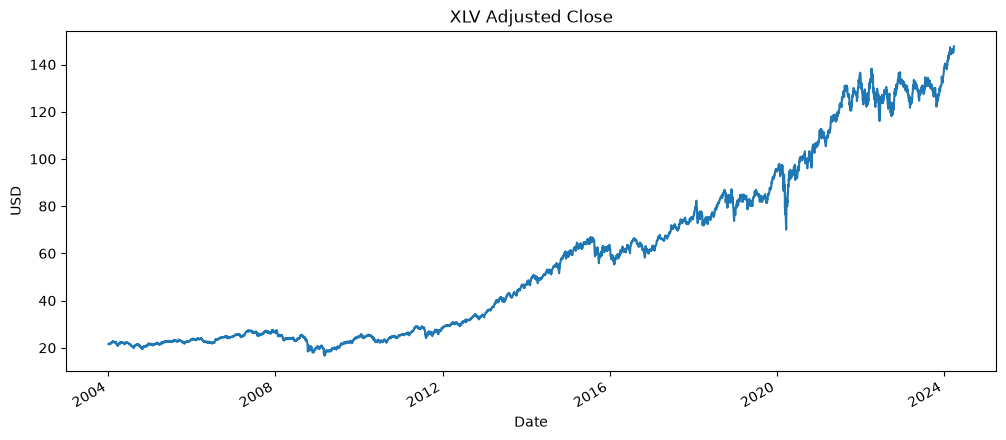

In [8]:
xlv_data["Adj Close"].plot(figsize=(12, 5), title="XLV Adjusted Close")
plt.ylabel("USD")
plt.show()

**Bonus**: The cell below plots the combined candlestick + volume chart for the last 15 months of data using Plotly.


In [9]:
data_since_2023 = xlv_data["2023-01-01":]

figure = make_subplots(specs=[[{"secondary_y": True}]])
figure.add_traces(
    go.Candlestick(
        x=data_since_2023.index,
        open=data_since_2023.Open,
        high=data_since_2023.High,
        low=data_since_2023.Low,
        close=data_since_2023.Close,
    ),
    secondary_ys=[True],
)
figure.add_traces(
    go.Bar(x=data_since_2023.index, y=data_since_2023.Volume, opacity=0.5),
    secondary_ys=[False],
)

figure.update_layout(
    title="XLV Candlestick Chart Since 2023",
    xaxis_title="Date",
    yaxis_title="Volume",
    yaxis2_title="Price",
    showlegend=False,
)
figure.update_yaxes(fixedrange=False)
figure.layout.yaxis2.showgrid = False
figure.show()

### 1.2. Data for The Volatility Index `VIX`


As before, we have downloaded daily data for the volatility index [(INDEXCBOE: VIX)](https://www.cboe.com/tradable_products/vix/) over the same time period using `yfinance` and provided it to you in a CSV file named `vix_data.csv`. Load the data into a variable named `vix_data`. Make sure to set the index and parse the dates correctly.


In [10]:
vix_data = pd.read_csv("vix_data.csv", index_col=0, parse_dates=True)
print(vix_data.shape, "| NaN rows:", int(vix_data.isna().any(axis=1).sum()))

(5094, 6) | NaN rows: 0


Plot a line chart of the `Adj Close` value of the VIX using your method of choice (e.g. `plotly` or `matplotlib`).


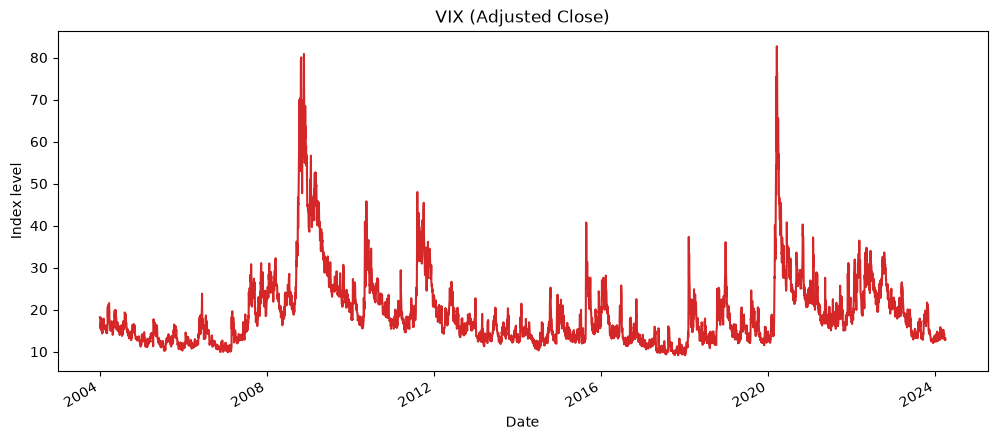

In [11]:
vix_data["Adj Close"].plot(figsize=(12, 5), title="VIX (Adjusted Close)", color="tab:red")
plt.ylabel("Index level")
plt.show()

### 1.3. Google Trends Data


The **monthly** evolution of search interest in the term "recession" in the U.S. over the period of interest (Jan. 2003 - Mar. 2024) from the Google Trends website has been provided to you as a CSV file. We will load this data using Pandas into a DataFrame named `google_trends_data`, set the index column of the DataFrame to the "`Month`" column from the CSV and have Pandas try and parse these dates automatically.

> Note: The "Month" column in the CSV is in "YYYY-MM" format.


In [12]:
google_trends_data = pd.read_csv("GoogleTrendsData.csv", index_col="Month", parse_dates=True)

As noted above, the CSV lists **monthly** search trends data and the `Month` column is in YYYY-MM format. How has Pandas interpreted and parsed these into specific dates? Take a look at `google_trends_data`'s index.


In [13]:
google_trends_data.index

DatetimeIndex(['2004-01-01', '2004-02-01', '2004-03-01', '2004-04-01',
               '2004-05-01', '2004-06-01', '2004-07-01', '2004-08-01',
               '2004-09-01', '2004-10-01',
               ...
               '2023-06-01', '2023-07-01', '2023-08-01', '2023-09-01',
               '2023-10-01', '2023-11-01', '2023-12-01', '2024-01-01',
               '2024-02-01', '2024-03-01'],
              dtype='datetime64[us]', name='Month', length=243, freq=None)

We would have liked to assign the data points to the last day of the respective months, as this data would have been available at the _end_ of each period. Shift the index column of `google_trends_data` to do this.

> Hint: You can use `pd.offsets.MonthEnd()` from Pandas.


In [14]:
google_trends_data.index = google_trends_data.index + pd.offsets.MonthEnd(0)

Run the cell below to visualize this data as a line plot.

> **Note from Google:** "Numbers represent search interest relative to the highest point on the chart for the given region and time. A value of 100 is the peak popularity for the term. A value of 50 means that the term is half as popular. A score of 0 means there was not enough data for this term."


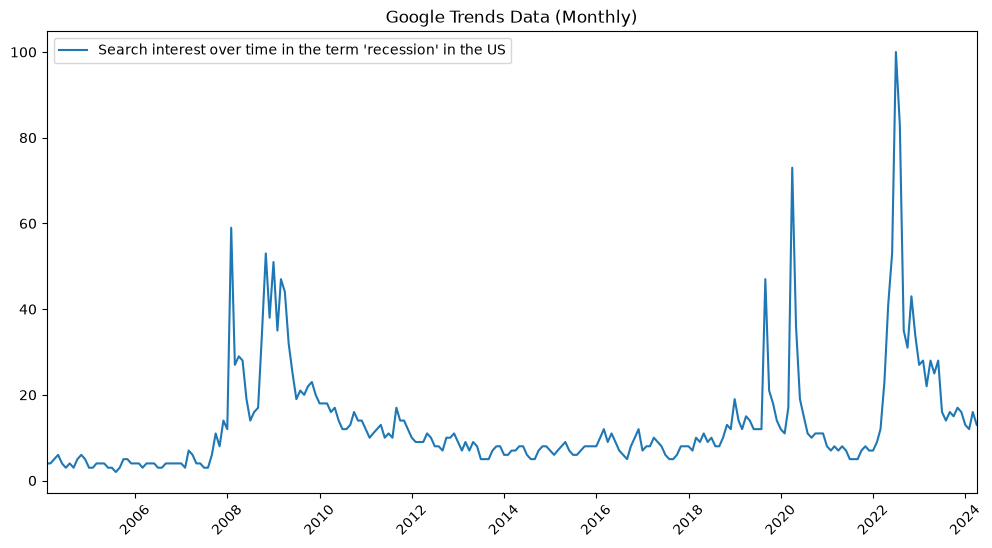

In [15]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(google_trends_data)
date_fmt = mdates.DateFormatter("%Y-%m")
plt.xlim(google_trends_data.index[0], google_trends_data.index[-1])
plt.xticks(rotation=45)
plt.title("Google Trends Data (Monthly)")
plt.legend(["Search interest over time in the term 'recession' in the US"])
plt.show()

But not every month-end is a trading day. Also, what value should the model train on for all the days in between month-ends? Below, we have provided you with code to convert the monthly data to daily and interpolate the end-of-month values to get all the in-between values. You will be using this new `google_trends_daily` data going forward.


In [16]:
google_trends_daily = google_trends_data.resample('D').asfreq().interpolate(method='linear')

In [17]:
# # The shape of the chart should not have changed
# google_trends_daily.plot.line(title="Google Trends Data (Daily)", figsize=(12, 6)).legend(
#     labels=['Search interest over time in the term "recession" in the US']
# );

## 2. Feature Engineering and Analysis


In this section, you will create a new DataFrame called `data` which will house all of the features as well as the prediction target. Then you will analyze the features and look for potentially problematic features.

Start by running the cell below to create `data` as an empty DataFrame with just an index that matches `XLV`'s.


In [18]:
data = pd.DataFrame(index=xlv_data.index)

### 2.1. Feature Engineering


#### 2.1.1. Month and Weekday


Add the `month` and `weekday` columns to `data` as categorical features (integer labels) from its index.


In [19]:
data["month"] = data.index.month
data["weekday"] = data.index.day_of_week   # Monday=0 ... Friday=4

You do not want to train a model using these columns as they are, because the numbers themselves and the inherent "order" of months and weekdays do not really have any significance, but the model may interpret them as meaningful. You could either (a) use one-hot encoding to turn each category to a separate binary feature, or (b) treat them as cyclical features. The choice is somewhat arbitrary and depends on how important a "feature" you believe the cyclicality to be.

Below, you will:

- Treat `month` as a cyclical feature, creating two features (`month_sin` and `month_cos`). (👉 See: [Trigonometric features](https://scikit-learn.org/stable/auto_examples/applications/plot_cyclical_feature_engineering.html#trigonometric-features))
- One-hot-encode `weekday` and create five additional features of type `int32` (one for each business day) with the `weekday` prefix. (👉 See: [`pandas.get_dummies()`](https://pandas.pydata.org/docs/reference/api/pandas.get_dummies.html))
- Make sure the original `month` and `weekday` columns are no longer present in `data`. (`drop()` them if necessary.)


In [20]:
# Treat `month` as a "cyclical" feature with a period of 12 months.
data["month_sin"] = np.sin(2 * np.pi * data["month"] / 12)
data["month_cos"] = np.cos(2 * np.pi * data["month"] / 12)

# Drop the original `month` column.
data = data.drop(columns=["month"])

# Treat `weekday` as a "categorical" feature and one-hot-encode it.
data = pd.get_dummies(data, columns=["weekday"], prefix="weekday", dtype="int32")
data.head()

,month_sin,month_cos,weekday_0,weekday_1,weekday_2,weekday_3,weekday_4
Date,,,,,,,
2004-01-02,0.5,0.866025,0,0,0,0,1
2004-01-05,0.5,0.866025,1,0,0,0,0
2004-01-06,0.5,0.866025,0,1,0,0,0
2004-01-07,0.5,0.866025,0,0,1,0,0
2004-01-08,0.5,0.866025,0,0,0,1,0


#### 2.1.2. Historical Returns


Next, add features for historical returns of the XLV ETF from its `Adj Close` column. For each date, calculate rolling **simple** returns over the past 1, 5, 10 and 20 days. Create 4 columns in `data` named `ret_#d_hist` where `#` is the lookback period. The list `hist_ret_lookbacks` is provided if you wish to use it.


In [21]:
# Create features for 1-day, 5-day, 10-day and 20-day historical returns
hist_ret_lookbacks = [1, 5, 10, 20]
for n_days in hist_ret_lookbacks:
    data[f"ret_{n_days}d_hist"] = xlv_data["Adj Close"].pct_change(n_days)

The cell below plots the histograms of the returns you just calculated. They should look normally distributed around zero.


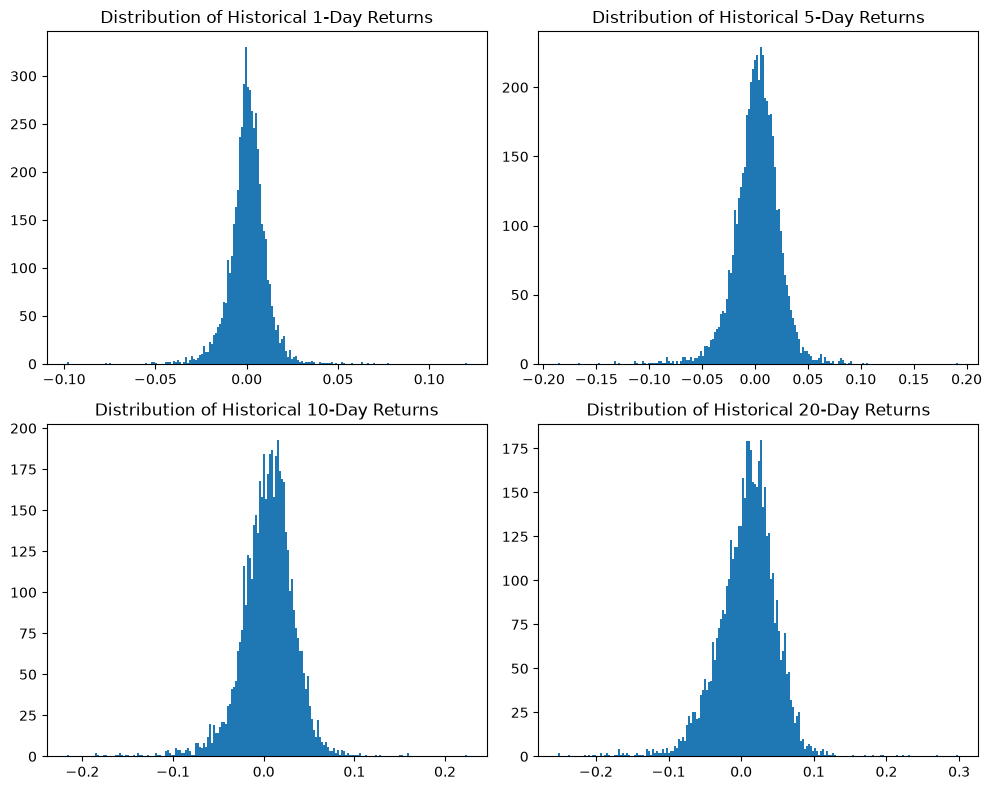

In [22]:
hist_ret_lookbacks = [1, 5, 10, 20] # In case it was deleted from the previous cell

fig, axs = plt.subplots(2, 2, figsize=(10, 8))


def plot_hist_returns(ax, data, col, title):
    ax.hist(data[col], bins=200)
    ax.set_title(title)


for i, n_days in enumerate(hist_ret_lookbacks):
    plot_hist_returns(
        axs[i // 2, i % 2], data, f"ret_{n_days}d_hist", f"Distribution of Historical {n_days}-Day Returns"
    )

plt.tight_layout()
plt.show()

#### 2.1.3. Trade Volumes

As trading volumes span several orders of magnitude, take the natural logarithm of `Volume` and use it as a feature instead. This helps emphasize variations in its lower range. Use `np.log()` and call this new feature `log_volume`.

**Note:** For tree-based models such as Decision Trees and Random Forests, scaling is not necessary. But feature scaling becomes critically important if you use other model types (e.g. distance-based models).


In [23]:
data["log_volume"] = np.log(xlv_data["Volume"])

#### 2.1.4. Technical Indicators

Add a feature named `ibs` which is calculated as (Close - Low) / (High - Low). This measure, a number between zero and one and sometimes referred to as the "Internal Bar Strength", denotes how "strong" the closing price is relative to the high and low prices within the same period.
> **Note:** Make sure to use `Close` (not `Adj Close`).

In [24]:
# Engineer the technical indicator "Internal Bar Strength" (IBS) from XLV's price data
data["ibs"] = (xlv_data["Close"] - xlv_data["Low"]) / (xlv_data["High"] - xlv_data["Low"])

Run the cell below to add a few more technical indicators, including Bollinger Band features and indicators, as well as the Relative Strength Index (RSI).

In [25]:
# Get some more technical indicators using the `ta` library

indicator_bb = BollingerBands(close=xlv_data["Close"], window=20, window_dev=2)
indicator_rsi = RSIIndicator(close=xlv_data["Close"], window=14)

# Add Bollinger Bands features
data["bb_bbm"] = indicator_bb.bollinger_mavg()
data["bb_bbh"] = indicator_bb.bollinger_hband()
data["bb_bbl"] = indicator_bb.bollinger_lband()

# Add Bollinger Band high and low indicators
data["bb_bbhi"] = indicator_bb.bollinger_hband_indicator()
data["bb_bbli"] = indicator_bb.bollinger_lband_indicator()

# Add Width Size and Percentage Bollinger Bands
data["bb_bbw"] = indicator_bb.bollinger_wband()
data["bb_bbp"] = indicator_bb.bollinger_pband()

# Add RSI
data["rsi"] = indicator_rsi.rsi()

#### 2.1.5. The Target of Prediction

Add the column `tgt_is_pos_ret_5d_fut` as type `int` to `data`, denoting whether forward-looking 5-day returns on each day are positive (a value of `1`) or negative (a value of `0`).
> **Note:** Again, as before, calculte **simple** returns from the `Adj Close` column of `xlv_data`.

In [26]:
# Create the prediction target: an integer indicating whether future 5-day returns are positive (1) or negative (0)
# Forward 5-day simple return on day t = Adj Close(t+5) / Adj Close(t) - 1
fwd_ret_5d = xlv_data["Adj Close"].shift(-5) / xlv_data["Adj Close"] - 1
data["tgt_is_pos_ret_5d_fut"] = (fwd_ret_5d > 0).astype(int)

Run the cells below to get an idea of how balanced the distribution of the target variable is throughout the data.

In [27]:
target_col_name = "tgt_is_pos_ret_5d_fut"
# Inspect the distribution of the target variable
target_value_counts = data[target_col_name].value_counts()
target_value_counts / len(data)


tgt_is_pos_ret_5d_fut
1    0.566156
0    0.433844
Name: count, dtype: float64

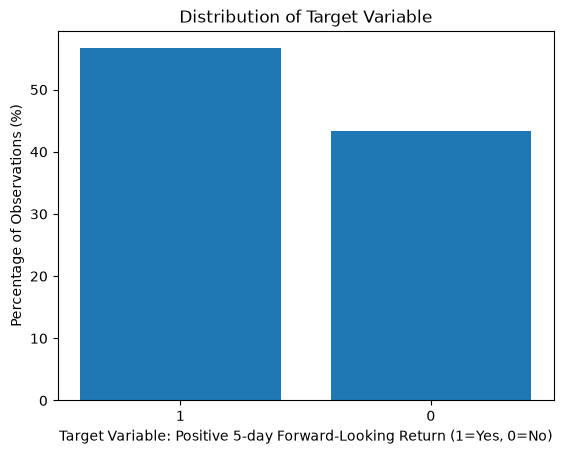

In [28]:
target_value_percentages = target_value_counts / len(data) * 100

plt.bar(target_value_percentages.index.astype(str), target_value_percentages.values)
plt.xlabel("Target Variable: Positive 5-day Forward-Looking Return (1=Yes, 0=No)")
plt.ylabel("Percentage of Observations (%)")
plt.title("Distribution of Target Variable")
plt.show()

Does the data look relatively balanced or grossly unbalanced in the distribution of the target variable? Why is this important?


In [29]:
answer = "Mildly imbalanced, not grossly: 56.6% of days are labeled 1 (followed by a positive 5-day return) and 43.4% are labeled 0. Label 0 covers 2,181 negative-return days (42.8%), 24 days with exactly zero return, and the last 5 rows, whose future return is not yet known (those 5 rows are dropped later). This matters because accuracy alone becomes misleading. A model that always predicts 'up' would already be right about 57% of the time without learning anything. Any model therefore has to be judged against that majority-class baseline, and also on precision, recall and F1 for each class."

#### 2.1.6. Stitching Everything Together

You will now add the `vix_data` and `google_trends_daily` as features to `data`. You will also rename the column corresponding to the VIX feature. Run the cell below to do so.

In [30]:
# Join with the Google Trends data and VIX data
data = data.join(google_trends_daily, how="left")
data = data.join(vix_data["Adj Close"], how="left")
data = data.rename(columns={"Adj Close": "vix"})

### 2.2. Further Data Preprocessing and Cleaning


While engineering new features, some `NaN` values were created. You now need to clean the combined DataFrame. Inspect `data` to see how many `NaN` values there are per column.

In [31]:
data.isna().sum()

month_sin                  0
month_cos                  0
weekday_0                  0
weekday_1                  0
weekday_2                  0
weekday_3                  0
weekday_4                  0
ret_1d_hist                1
ret_5d_hist                5
ret_10d_hist              10
ret_20d_hist              20
log_volume                 0
ibs                        0
bb_bbm                    19
bb_bbh                    19
bb_bbl                    19
bb_bbhi                    0
bb_bbli                    0
bb_bbw                    19
bb_bbp                    19
rsi                       13
tgt_is_pos_ret_5d_fut      0
recession_search_trend    20
vix                        0
dtype: int64

Some features, such as historical returns, RSI, Bollinger Bands and BB indicators cannot be calculated for the first `n` days due to their "rolling" nature. In general, missing values can sometimes be imputed with reasonable estimates. But here you will simply drop the rows containing them. The largest `n` is `20`, corresponding to the calculation of 20-day historical returns. Drop the first 20 rows of `data`.


In [32]:
data = data.iloc[20:]
print(data.shape)

(5074, 24)


Are there any more missing values?

In [33]:
data.isna().sum()[data.isna().sum() > 0] if data.isna().sum().sum() else print("No missing values remain.")

No missing values remain.


Even if there aren't, you remember that when you calculated the target variable (`tgt_is_pos_ret_5d_fut`) based on forward-looking 5-day rolling returns, you could not have known future returns for the last five days of `data`! Therefore the last 5 rows of data should be dropped.


In [34]:
# The target for the last 5 rows would need prices we do not have, so drop them
data = data.iloc[:-5]
print(data.shape)

(5069, 24)


Let us take a final look at the types and statistical characteristics of the set of features and targets.


In [35]:
data.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 5069 entries, 2004-02-02 to 2024-03-21
Data columns (total 24 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   month_sin               5069 non-null   float64
 1   month_cos               5069 non-null   float64
 2   weekday_0               5069 non-null   int32  
 3   weekday_1               5069 non-null   int32  
 4   weekday_2               5069 non-null   int32  
 5   weekday_3               5069 non-null   int32  
 6   weekday_4               5069 non-null   int32  
 7   ret_1d_hist             5069 non-null   float64
 8   ret_5d_hist             5069 non-null   float64
 9   ret_10d_hist            5069 non-null   float64
 10  ret_20d_hist            5069 non-null   float64
 11  log_volume              5069 non-null   float64
 12  ibs                     5069 non-null   float64
 13  bb_bbm                  5069 non-null   float64
 14  bb_bbh                  5069 non-

In [36]:
data.describe()

,month_sin,month_cos,weekday_0,weekday_1,weekday_2,weekday_3,weekday_4,ret_1d_hist,ret_5d_hist,ret_10d_hist,ret_20d_hist,log_volume,ibs,bb_bbm,bb_bbh,bb_bbl,bb_bbhi,bb_bbli,bb_bbw,bb_bbp,rsi,tgt_is_pos_ret_5d_fut,recession_search_trend,vix
count,5.069000e+03,5.069000e+03,5069.000000,5069.000000,5069.000000,5069.000000,5069.000000,5069.000000,5069.000000,5069.000000,5069.000000,5069.000000,5069.000000,5069.000000,5069.000000,5069.000000,5069.000000,5069.000000,5069.000000,5069.000000,5069.000000,5069.000000,5069.000000,5069.000000
mean,-2.838770e-03,-7.572043e-03,0.186625,0.205169,0.205761,0.202210,0.200237,0.000427,0.002097,0.004185,0.008346,15.409240,0.534112,65.190507,67.147802,63.233213,0.060761,0.054054,5.948065,0.567198,53.683015,0.565989,13.290878,19.099797
std,7.097124e-01,7.045852e-01,0.389648,0.403865,0.404296,0.401687,0.400217,0.010493,0.021729,0.029813,0.040486,1.081947,0.307988,36.490915,37.643799,35.382734,0.238916,0.226147,3.644471,0.326476,11.253373,0.495675,12.478947,8.747777
min,-1.000000e+00,-1.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,-0.098610,-0.185835,-0.217250,-0.251548,10.980195,0.000000,23.217500,24.569328,20.419952,0.000000,0.000000,1.165471,-0.452267,13.539141,0.000000,2.032258,9.140000
25%,-8.660254e-01,-8.660254e-01,0.000000,0.000000,0.000000,0.000000,0.000000,-0.004458,-0.009204,-0.011609,-0.013455,15.158428,0.259258,32.040500,32.789038,31.152674,0.000000,0.000000,3.790178,0.310053,46.019133,0.000000,6.322581,13.380000
50%,-2.449294e-16,-1.836970e-16,0.000000,0.000000,0.000000,0.000000,0.000000,0.000633,0.002931,0.005917,0.011537,15.703898,0.546873,57.274000,58.749715,54.721044,0.000000,0.000000,5.052307,0.622857,54.080883,1.000000,9.225806,16.549999
75%,8.660254e-01,5.000000e-01,0.000000,0.000000,0.000000,0.000000,0.000000,0.005891,0.014858,0.021953,0.032932,16.075052,0.818179,90.399500,93.205837,87.412764,0.000000,0.000000,7.015371,0.832430,61.812445,1.000000,14.931034,22.129999
max,1.000000e+00,1.000000e+00,1.000000,1.000000,1.000000,1.000000,1.000000,0.120547,0.192308,0.223935,0.299116,18.012264,1.000000,146.183501,148.369194,144.631724,1.000000,1.000000,32.354816,1.349959,85.413254,1.000000,100.000000,82.690002


### 2.3. Correlation Analysis


Correlation analysis can be a rough and early form of feature importance analysis. Features that are highly correlated (in either direction) with each other but not with the target variable, are a sign of multicollinearity problems, which means they may not contribute much additional information in predicting the target. In fact, depending on the algorithm used, multicollinearity may result in stability and reliability issues. Checking the correlation matrix can be helpful in identifying such features.  

Plot the heatmap of the correlation matrix of features/target and identify a cluster of 3 features that are almost certainly collinear. (Hint: `bb_bbm` is one of them.) You can pass the correlation matrix directly to [Seaborn's `heatmap()` method](https://seaborn.pydata.org/generated/seaborn.heatmap.html).

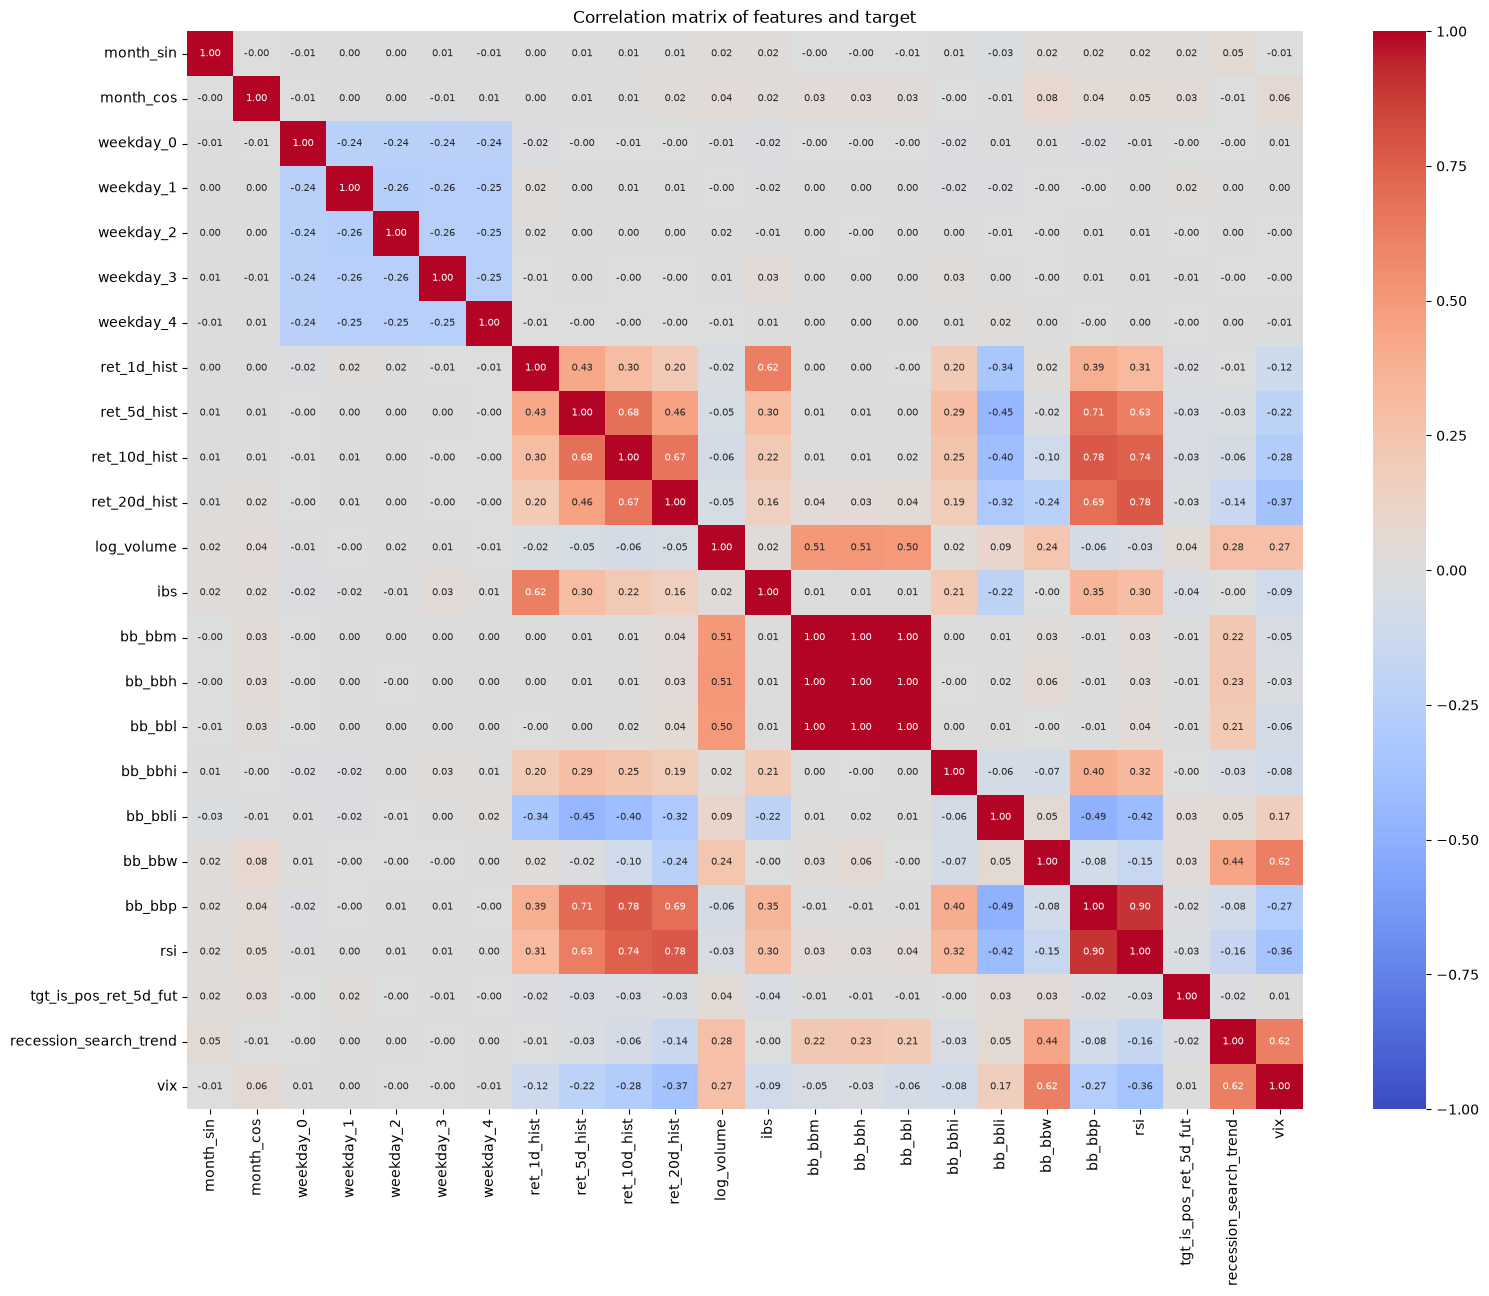

        bb_bbm  bb_bbh  bb_bbl
bb_bbm  1.0000  0.9994  0.9993
bb_bbh  0.9994  1.0000  0.9975
bb_bbl  0.9993  0.9975  1.0000


In [37]:
corr_matrix = data.corr()
plt.figure(figsize=(18, 14))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, annot_kws={"size": 7})
plt.title("Correlation matrix of features and target")
plt.show()
# The three Bollinger Band levels move almost one-for-one with each other
print(corr_matrix.loc[["bb_bbm", "bb_bbh", "bb_bbl"], ["bb_bbm", "bb_bbh", "bb_bbl"]].round(4))

In such scenarios, we usually eliminate all but one of the collinear features. Keep `bb_bbm` and drop the other two features that are highly linearly related to it.

In [38]:
# Keep bb_bbm and drop the two bands that are almost perfectly collinear with it
data = data.drop(columns=["bb_bbh", "bb_bbl"])

There is also one feature that is very highly correlated with `rsi` (which makes intuitive sense, as it, too, is a measure of relative strength). Find it an eliminate it, leaving `rsi` intact.

In [39]:
# The feature most correlated with rsi (other than rsi itself)
rsi_corr = data.corr()["rsi"].drop(["rsi", "tgt_is_pos_ret_5d_fut"]).abs().sort_values(ascending=False)
print(rsi_corr.head(3).round(4))
data = data.drop(columns=[rsi_corr.index[0]])
print("Dropped:", rsi_corr.index[0])

bb_bbp          0.899
ret_20d_hist    0.781
ret_10d_hist    0.743
Name: rsi, dtype: float64
Dropped: bb_bbp


Plot the heatmap of the new, reduced correlation matrix.

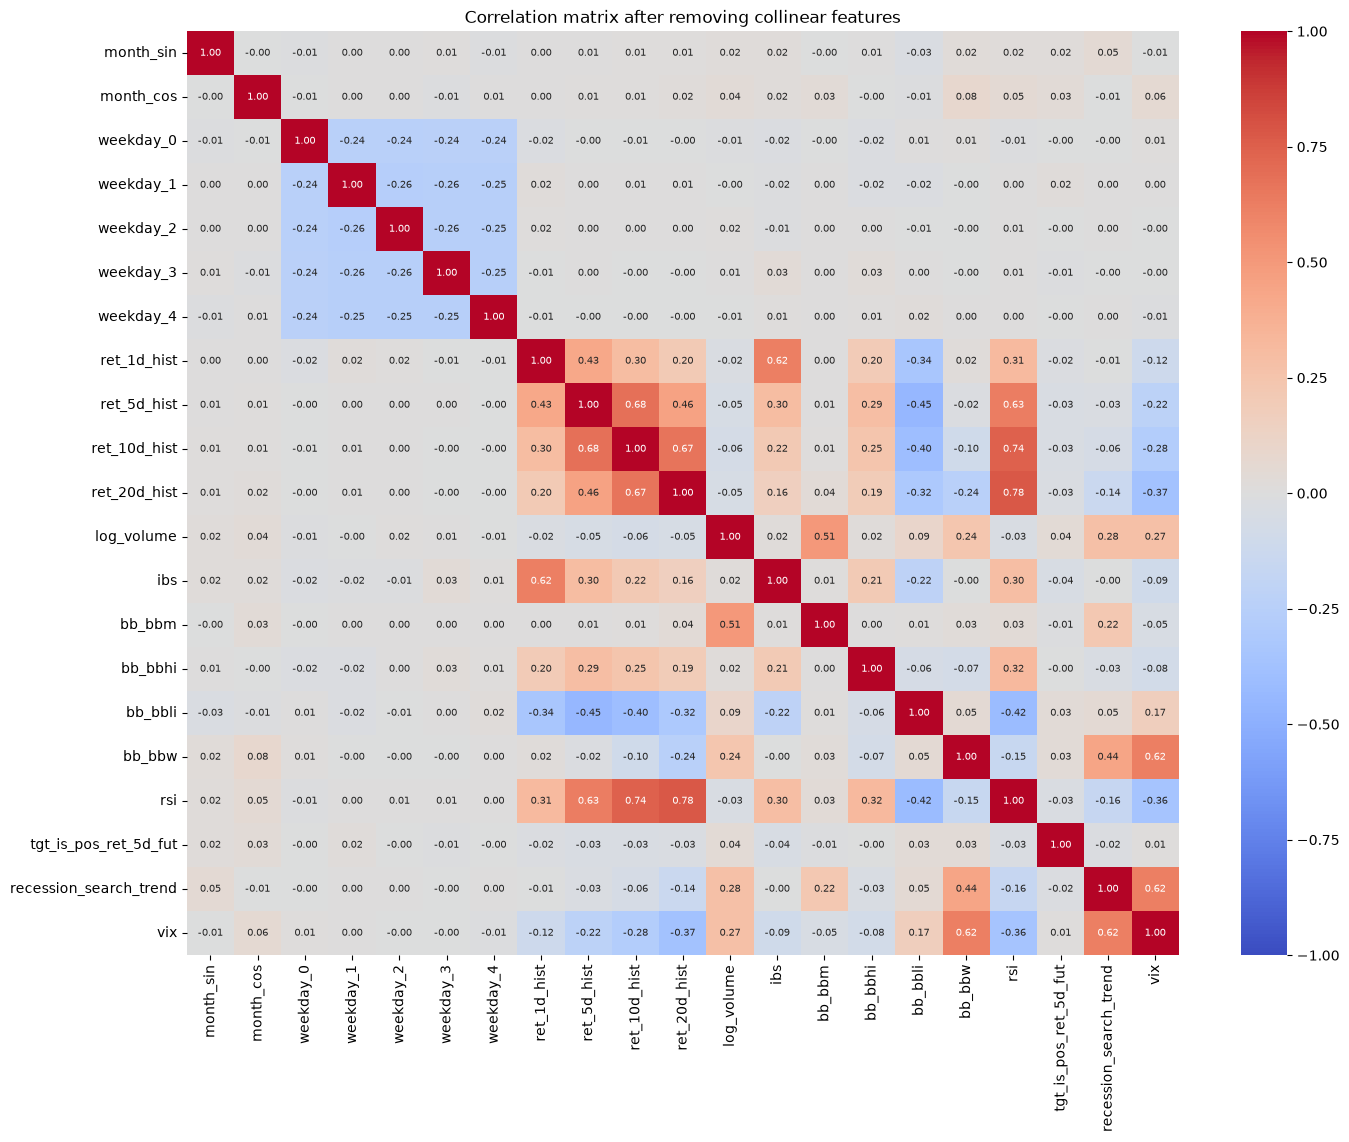

In [40]:
corr_matrix_reduced = data.corr()
plt.figure(figsize=(16, 12))
sns.heatmap(corr_matrix_reduced, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, annot_kws={"size": 7})
plt.title("Correlation matrix after removing collinear features")
plt.show()

Features that are highly correlated (negatively or positively) **with the target variable** are likely more important. Which two (2) independent variables (features) are correlated more than 4% (**in either direction**) with the boolean target variable denoting whether 5-day future returns are positive?


In [41]:
target_corr = data.corr()["tgt_is_pos_ret_5d_fut"].drop("tgt_is_pos_ret_5d_fut")
print(target_corr.abs().sort_values(ascending=False).head(5).round(4))
top_two = target_corr[target_corr.abs() > 0.04]
answer = "ibs (correlation of -0.044 with the target) and log_volume (+0.043). A weak close within the day's range (low IBS) is slightly more often followed by a positive 5-day return, a mild mean-reversion effect. Higher trading volume is slightly more often followed by a positive 5-day return. Both correlations are very small, so neither is a strong signal on its own."

ibs             0.0443
log_volume      0.0432
month_cos       0.0341
ret_10d_hist    0.0323
bb_bbw          0.0316
Name: tgt_is_pos_ret_5d_fut, dtype: float64


## 3. The Training-Validation-Testing Split


In this section, you will split the `data` set into two sets: the training and validation set, and the testing set. You will then come up with a baseline score so that you have a reference point for evaluating your model's performance.

**Note:** Technically, since you are not going to use classical statistics-based time-series prediction methods (such as ARIMA), you can shuffle the data before splitting it. But for ease of interpretability and backtesting, you may as well keep the data in its original order. This is fine as long as the distributions of features and the target variable do not significantly shift over time. - And that is an important assumption related to drift analysis, which was covered in the course, but we will not get to in this project.

### 3.1. The Split


It is time to split the data, temporally, into the training + validation and testing sets. You will train and optimize (i.e. cross-validate) your model on the first 80% of the data, and use the remaining 20% for the test set (i.e. to evaluate the performance of your model). Use the `train_test_split()` method from scikit-learn's `model_selection` module to perform the split.
> **Note:** Please make sure to set `shuffle=False` and `random_state=RANDOM_STATE`.

In [42]:
target_col_name = "tgt_is_pos_ret_5d_fut"
X = data.drop(columns=[target_col_name])
y = data[target_col_name]

X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.2, shuffle=False, random_state=RANDOM_SEED)
print(f"Train + validation: {X_train_val.index.min().date()} to {X_train_val.index.max().date()} ({len(X_train_val)} rows)")
print(f"Test:               {X_test.index.min().date()} to {X_test.index.max().date()} ({len(X_test)} rows)")

Train + validation: 2004-02-02 to 2020-03-11 (4055 rows)
Test:               2020-03-12 to 2024-03-21 (1014 rows)


### 3.2. Baseline Model and Score


Earlier, you inspected the distribution of the target variable across the entire data set. Run the cell below to analyze at the distribution of the target variable in each split.

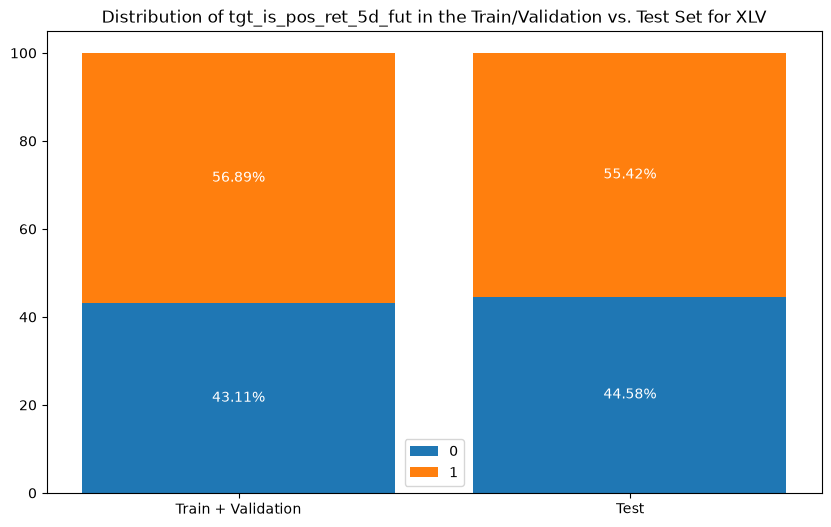

In [43]:
train_val_pct = y_train_val.value_counts(normalize=True) * 100
test_pct = y_test.value_counts(normalize=True) * 100

categories = ["Train + Validation", "Test"]
zero_counts = [train_val_pct[0], test_pct[0]]
one_counts = [train_val_pct[1], test_pct[1]]

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(categories, zero_counts, label="0")
ax.bar(categories, one_counts, bottom=zero_counts, label="1")

# Add text annotations
for i, (zero, one) in enumerate(zip(zero_counts, one_counts)):
    ax.text(i, zero / 2, f"{zero:.2f}%", ha="center", va="center", color="white")
    ax.text(
        i,
        zero + one / 2,
        f"{one:.2f}%",
        ha="center",
        va="center",
        color="white",
    )
ax.set_title(f"Distribution of {target_col_name} in the Train/Validation vs. Test Set for XLV")
ax.legend()

plt.show()

If you were to devise a simple model that naively always predicted the majority class, what would the accuracy score of your model be on the training+validation set? How about on the testing set? Consider the latter your baseline score, i.e. a reference score to compare your more sophisticated model's performace to.

In [44]:
majority_class = y_train_val.mode()[0]   # the naive model always predicts the majority class it saw in training
baseline_accuracy_train_val_score = (y_train_val == majority_class).mean()
baseline_accuracy_test_score = (y_test == majority_class).mean()
print(f"Majority class: {majority_class}")
print(f"Baseline accuracy, train + validation: {baseline_accuracy_train_val_score:.4f}")
print(f"Baseline accuracy, test:               {baseline_accuracy_test_score:.4f}")

Majority class: 1
Baseline accuracy, train + validation: 0.5689
Baseline accuracy, test:               0.5542


## 4. Model Training and Tuning


In this section, you will train a `RandomForestClassifier`, a robust, versatile ensemble learning method that uses "bagging" (also known as "bootstrap aggregating") to train multiple Decision Trees. The technical details of the model are beyond the scope of this course, but you may read more about it [here](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html).

Run the cell below which defines a function that allows you to plot learning curves annotated with a hyperparameter named `max_depth` which you pass to it.

In [45]:
def plot_learning_curves(train_sizes, train_scores, test_scores, max_depth, axs):
    train_scores_mean = np.mean(train_scores, axis=1)
    train_scores_std = np.std(train_scores, axis=1)
    test_scores_mean = np.mean(test_scores, axis=1)
    test_scores_std = np.std(test_scores, axis=1)

    axs.fill_between(
        train_sizes,
        train_scores_mean - train_scores_std,
        train_scores_mean + train_scores_std,
        alpha=0.1,
        color="b",
    )
    axs.fill_between(
        train_sizes,
        test_scores_mean - test_scores_std,
        test_scores_mean + test_scores_std,
        alpha=0.1,
        color="r",
    )
    axs.plot(
        train_sizes,
        train_scores_mean,
        "o-",
        color="b",
        label="Average Score on Training Sets",
    )
    axs.plot(
        train_sizes,
        test_scores_mean,
        "o-",
        color="r",
        label="Average Score on Test Sets",
    )
    axs.set_xlabel("Training examples")
    axs.set_ylabel("Score")
    axs.set_title(f"Learning Curves (max_depth={max_depth})")
    axs.legend(loc="center left")
    axs.grid(True)

Below is the first iteration of your model. It uses the default values for most of its hyperparameters. We have only specified one hyperparameter, `max_depth=10`.

In [46]:
max_depth = 10
model = RandomForestClassifier(max_depth=max_depth, random_state=RANDOM_SEED, n_jobs=-1)

Use the `learning_curve()` method from scikit-learn's `model_selection` module to cross-validate your model, with `accuracy` as the `scoring` metric. Use 10%, 20%, 30%,... , and 100% of the training+validatin data, with 5-fold cross-validation.

In [47]:
train_sizes = np.linspace(0.1, 1.0, 10)

train_sizes, train_scores, test_scores = learning_curve(
    model, X_train_val, y_train_val, train_sizes=train_sizes, cv=5, scoring="accuracy", n_jobs=-1
)

Inspect the learning curves.

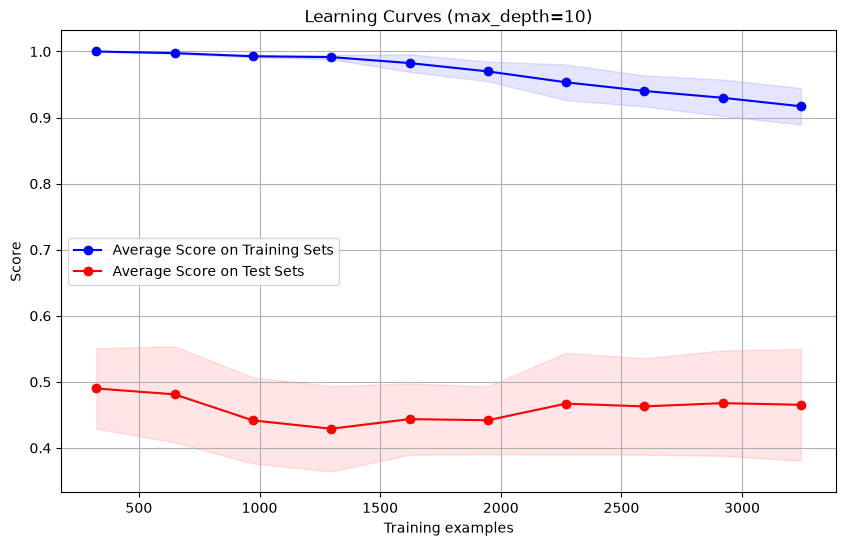

max_depth=10: training accuracy 0.9171 vs cross-validation accuracy 0.4654


In [48]:
figure = plt.figure(figsize=(10, 6))
axs = figure.gca()

plot_learning_curves(train_sizes, train_scores, test_scores, max_depth, axs)

plt.show()
print(f"max_depth={max_depth}: training accuracy {train_scores[-1].mean():.4f} vs cross-validation accuracy {test_scores[-1].mean():.4f}")

Wondering what effect different values of the `max_depth` hyperparameter have, you decide to experiment with lower (`10`) and higher (`20`) values of it to see how the plots change. Run the cell below to help you answer the questions that follow it.


max_depth=5: mean training accuracy at full size = 0.6786, mean cross-validation accuracy = 0.4880, gap = 0.1906


max_depth=10: mean training accuracy at full size = 0.9171, mean cross-validation accuracy = 0.4654, gap = 0.4517


max_depth=15: mean training accuracy at full size = 0.9991, mean cross-validation accuracy = 0.4562, gap = 0.5428


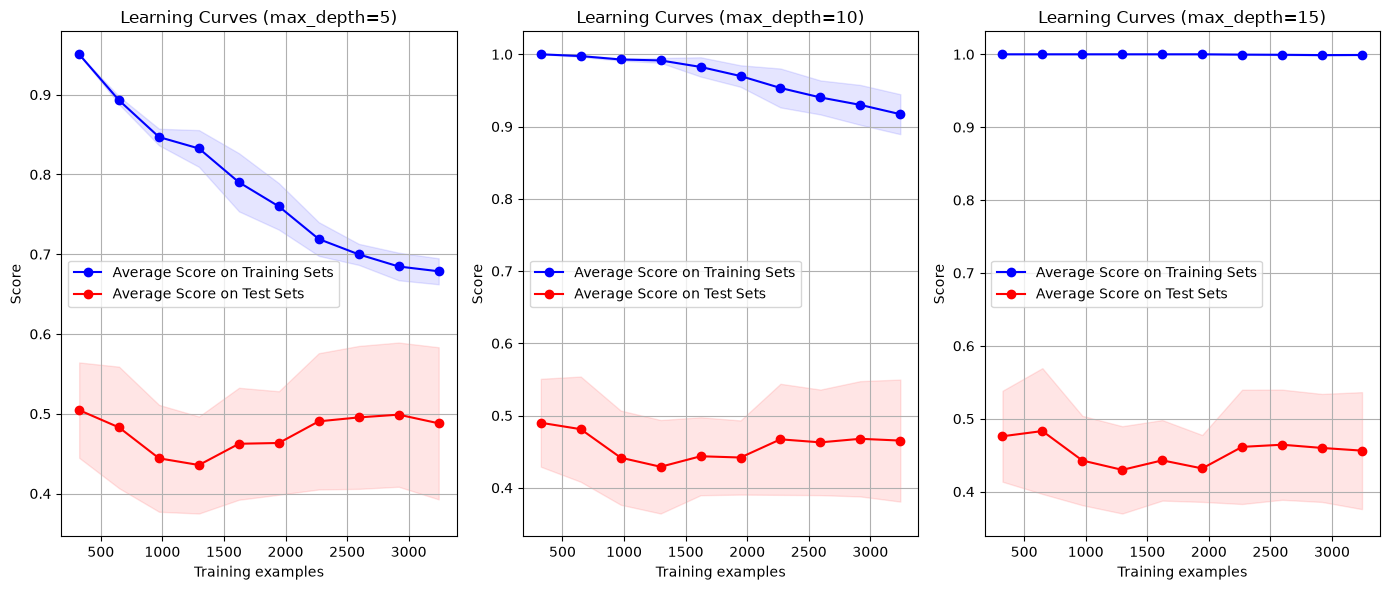

In [49]:
fig, axs = plt.subplots(1, 3, figsize=(14, 6))
max_depth_range = [5, 10, 15]
for i, max_depth in enumerate(max_depth_range):
    model = RandomForestClassifier(max_depth=max_depth, random_state=RANDOM_SEED, n_jobs=-1)
    train_sizes, train_scores, test_scores = learning_curve(
        model, X_train_val, y_train_val, train_sizes=train_sizes, cv=5, scoring="accuracy"
    )
    plot_learning_curves(train_sizes, train_scores, test_scores, max_depth, axs[i])
    print(f'max_depth={max_depth}: mean training accuracy at full size = {train_scores[-1].mean():.4f}, '
          f'mean cross-validation accuracy = {test_scores[-1].mean():.4f}, gap = {train_scores[-1].mean() - test_scores[-1].mean():.4f}')

plt.tight_layout()
plt.show()

With a value of `max_depth=15`, does your model overfit or underfit?


In [50]:
answer = "It overfits. At max_depth=15 the mean training accuracy is 0.999 while the mean cross-validation accuracy is only 0.456, a gap of 0.54. The trees memorize the training folds and do not generalize. The gap widens steadily as depth grows: 0.19 at depth 5 and 0.45 at depth 10."

With a value of `max_depth=15`, is your performance metric (accuracy score) more likely to improve with more training data or with higher model complexity?

In [51]:
answer = "More training data, not higher complexity. The model is already in the high-variance (overfitting) regime: near-perfect training accuracy and a large gap to validation accuracy. Adding complexity would widen that gap. More (and more relevant) data, or a simpler, more regularized model, is the way to close it. The learning curves also show the validation score is not rising much with more data, which suggests the features carry little predictive signal."

Random Forest Classifiers have several other hyperparameters, such as `min_samples_split` (default=2), `min_samples_leaf` (default=1) and `n_estimators` (default=100). So far, you have been tuning your model manually. But with all the possible combinations of hyperparameters, this is not tractable.  

Use grid search cross-validation (the `GridSearchCV` class from scikit-learn's `model_selection` module) to find the optimal combination of hyperparameters from the search space specified below:
- `max_depth` = 2, 3, 4 or 5
- `min_samples_leaf` = 1, 2, 3 or 4
- `n_estimators` = 50, 75, 100, 125, or 150

As before, use 5-fold cross-validation and accuracy as the `scoring` metric. Name your tuning model `search`.

> Note: Setting `n_jobs=-1` will allow Python to take advantage of parallel computing on your computer to speed up the training.

In [52]:
grid = {
    "max_depth": [2, 3, 4, 5],
    "min_samples_leaf": [1, 2, 3, 4],
    "n_estimators": [50, 75, 100, 125, 150],
}

search = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_SEED, n_jobs=-1), param_grid=grid, cv=5, scoring="accuracy", n_jobs=-1
)

search.fit(X_train_val, y_train_val)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [2, 3, ...], 'min_samples_leaf': [1, 2, ...], 'n_estimators': [50, 75, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Co

Run the cell below to see the top 5 best performing hyperparameter combinations.

In [53]:
cols = ["param_max_depth", "param_min_samples_leaf", "param_n_estimators", "mean_test_score", "std_test_score", "rank_test_score"]
pd.DataFrame(search.cv_results_).sort_values("rank_test_score")[cols].head()

,param_max_depth,param_min_samples_leaf,param_n_estimators,mean_test_score,std_test_score,rank_test_score
0,2,1,50,0.493958,0.101813,1
5,2,2,50,0.493958,0.101813,1
15,2,4,50,0.493958,0.101813,1
10,2,3,50,0.493958,0.101813,1
34,3,3,150,0.493218,0.104598,5


Looking at the results of GridSearchCV, which hyperparameters yield the highest mean test score?


In [54]:
best_max_depth = search.best_params_["max_depth"]
best_min_samples_leaf = search.best_params_["min_samples_leaf"]
best_n_estimators = search.best_params_["n_estimators"]
print(search.best_params_, f"best mean CV accuracy = {search.best_score_:.4f}")

{'max_depth': 2, 'min_samples_leaf': 1, 'n_estimators': 50} best mean CV accuracy = 0.4940


Looking more closely at the DataFrame of top 5 results, varying which hyperparameter did not seem to have any effect, at least in the top-ranking score?

In [55]:
answer = "min_samples_leaf. The four top-ranked combinations all have max_depth=2 and n_estimators=50, differ only in min_samples_leaf (1, 2, 3 and 4), and share exactly the same mean test score (0.4940). With such shallow trees, changing the minimum leaf size between 1 and 4 did not change the cross-validated accuracy. Depth and the number of trees drive the result here, not leaf size."

## 5. Model Evaluation and Interpretation


In this section, you will evaluate the performance metrics of the best model you found in the previous section and analyze feature importance in relation to model performance.

### 5.1. Evaluation (Performance Metrics)


It is finally time to train your model on the entire training + validation set with the optimal set of hyperparameters you just found, and evaluate its performance on the test set.  

Train (`fit()`) a `RandomForestClassifier` on the training data with the optimal combination of hyperparameters you found in the previous section. Name it 'clf'.

> **Note:** Remember to set `random_state=RANDOM_SEED` for consistency of results, and set `n_jobs=-1` to automatically speed up the run.

In [56]:
clf = RandomForestClassifier(
    max_depth=best_max_depth, min_samples_leaf=best_min_samples_leaf, n_estimators=best_n_estimators,
    random_state=RANDOM_SEED, n_jobs=-1,
)
clf.fit(X_train_val, y_train_val)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",50
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total num

Store your trained model's predictions on the **testing** set in a variable named `y_test_pred`.

In [57]:
y_test_pred = clf.predict(X_test)

Complete the Python dictionary in the code cell below to evaluate your model and answer the questions that follow.

In [58]:
evaluation = {
    "accuracy": accuracy_score(y_test, y_test_pred),
    "precision": precision_score(y_test, y_test_pred, zero_division=0),
    "recall": recall_score(y_test, y_test_pred, zero_division=0),
    "f1": f1_score(y_test, y_test_pred, zero_division=0),
}
display(evaluation)

{'accuracy': 0.5542406311637081,
 'precision': 0.5545634920634921,
 'recall': 0.994661921708185,
 'f1': 0.7121019108280254}

Explain, in words and citing the actual numbers from the evaluation report above, what the **precision** and **recall** scores mean.

In [59]:
answer = "Precision is 0.555: of the days the model predicted 'up' (1,008 of 1,014 test days), 55.5% were actually followed by a positive 5-day return. Recall is 0.995: of the 562 test days that really were followed by a positive return, the model flagged 559. The recall is high only because the model predicts 'up' almost every day (it predicted 'down' just 6 times). It catches nearly every up-move by never committing to a down call, so it has almost no ability to identify down-moves (recall of 0.01 for class 0)."

Run the cell below to get a more detailed report.

In [60]:
print(classification_report(y_test, y_test_pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.50      0.01      0.01       452
           1       0.55      0.99      0.71       562

    accuracy                           0.55      1014
   macro avg       0.53      0.50      0.36      1014
weighted avg       0.53      0.55      0.40      1014



How many True Negatives, False Negatives, False Positives and True Positives did the model predict on the test set? Find out using the `confusion_matrix()` method from scikit-learn's `metrics` module. 

In [61]:
confusion_matrix(y_test, y_test_pred)

array([[  3, 449],
       [  3, 559]])

Answer the question from earlier.
> Note: Feel free to rename the variables. We will not reference them later.

In [62]:
num_TrueNeg, num_FalsePos, num_FalseNeg, num_TruePos = confusion_matrix(y_test, y_test_pred).ravel()
print(f"True negatives: {num_TrueNeg}, False negatives: {num_FalseNeg}, False positives: {num_FalsePos}, True positives: {num_TruePos}")

True negatives: 3, False negatives: 3, False positives: 449, True positives: 559


Is the model overfitting or underfitting? Did it manage to capture the variance on the training set but fail to generalize to the testing set? Take a look at the `classification_report()` and `confusion_matrix()` on the **training** data.

In [63]:
y_train_val_pred = clf.predict(X_train_val)
print(classification_report(y_train_val, y_train_val_pred, zero_division=0))

              precision    recall  f1-score   support

           0       1.00      0.00      0.01      1748
           1       0.57      1.00      0.73      2307

    accuracy                           0.57      4055
   macro avg       0.78      0.50      0.37      4055
weighted avg       0.76      0.57      0.42      4055


In [64]:
confusion_matrix(y_train_val, y_train_val_pred)

array([[   6, 1742],
       [   0, 2307]])

How does your model's performance compare to the baseline in terms of `accuracy`?


In [65]:
answer = "It matches the baseline: test accuracy 0.5542 versus a majority-class baseline of 0.5542. In practice the tuned model behaves like the naive 'always up' rule. It also underfits rather than overfits. Training accuracy is 0.570, only slightly above the training-set baseline of 0.569 (6 more correct days out of 4,055), so the depth-2 forest did not capture meaningful structure even in the data it was trained on."

How do the `precision` and `recall` of your model compare to those of the baseline model?

In [66]:
answer = "They are virtually identical. The always-'up' baseline has precision equal to the share of up-days in the test set (0.554) and recall of 1.0 for class 1. The model scores 0.555 precision and 0.995 recall. It adds no measurable value over the baseline on either metric."

### 5.2. Revisiting Feature Importance


You decide to see if there are any features that are not contributing significantly to the performance of the model. Use the `feature_importances_` property of your classifier.


,importance
recession_search_trend,0.1205
log_volume,0.1131
vix,0.0953
ibs,0.0881
ret_10d_hist,0.0869
bb_bbm,0.0851
rsi,0.0769
bb_bbw,0.0755
ret_5d_hist,0.0740
month_cos,0.0669


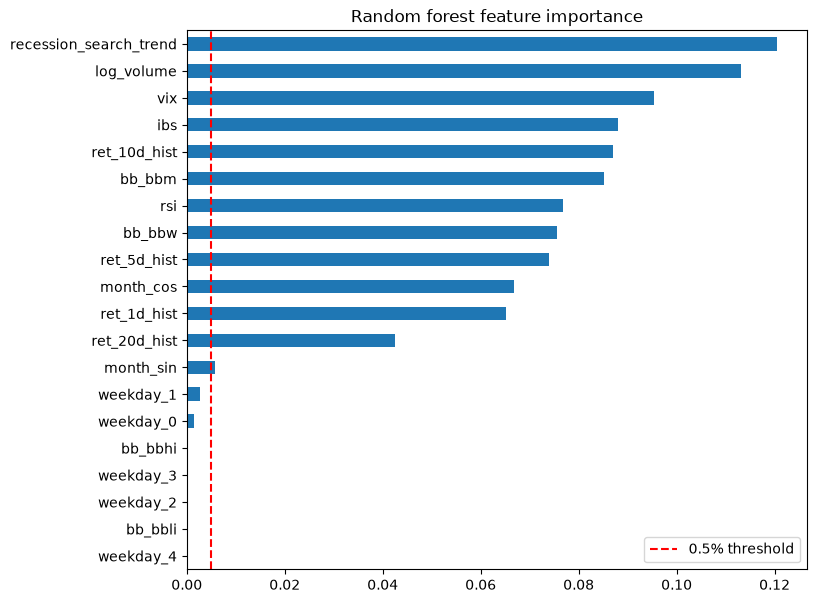

In [67]:
feature_importances = pd.Series(clf.feature_importances_, index=X_train_val.columns).sort_values(ascending=False)
display(feature_importances.to_frame("importance").round(4))
feature_importances.sort_values().plot.barh(figsize=(8, 7), title="Random forest feature importance")
plt.axvline(0.005, color="red", linestyle="--", label="0.5% threshold")
plt.legend()
plt.show()

Create a new training set named `X_train_val_reduced` and a new testing set named `X_test_reduced` by eliminating any features from the old train/test sets that had a feature importance of less than `0.5%`.

In [68]:
# Drop features that have an importance of less than 0.5%
feats_to_drop = feature_importances[feature_importances < 0.005].index.tolist()
print("Dropping:", feats_to_drop)
X_train_val_reduced = X_train_val.drop(columns=feats_to_drop)
X_test_reduced = X_test.drop(columns=feats_to_drop)

Dropping: ['weekday_1', 'weekday_0', 'weekday_4', 'weekday_3', 'weekday_2', 'bb_bbli', 'bb_bbhi']


Re-do your grid search cross-validation with the same grid of hyperparameters as before but with the **reduced** feature set.

In [69]:
model = RandomForestClassifier(random_state=RANDOM_SEED, n_jobs=-1)

search = GridSearchCV(model, param_grid=grid, cv=5, scoring="accuracy", n_jobs=-1)

search.fit(X_train_val_reduced, y_train_val)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [2, 3, ...], 'min_samples_leaf': [1, 2, ...], 'n_estimators': [50, 75, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Co

In [70]:
cols = ["param_max_depth", "param_min_samples_leaf", "param_n_estimators", "mean_test_score", "std_test_score", "rank_test_score"]
pd.DataFrame(search.cv_results_).sort_values("rank_test_score")[cols].head()

,param_max_depth,param_min_samples_leaf,param_n_estimators,mean_test_score,std_test_score,rank_test_score
1,2,1,75,0.493711,0.101571,1
6,2,2,75,0.493711,0.101571,1
12,2,3,100,0.493711,0.102962,1
11,2,3,75,0.493711,0.101571,1
17,2,4,100,0.493711,0.102962,1


In [71]:
search.best_params_

{'max_depth': 2, 'min_samples_leaf': 1, 'n_estimators': 75}

Train a new classifier on the reduced feature set with the best hyperparameters combination from the new grid search and then inspect its accuracy on the test set (with the **reduced** feature set).

In [72]:
clf = RandomForestClassifier(**search.best_params_, random_state=RANDOM_SEED, n_jobs=-1)
clf.fit(X_train_val_reduced, y_train_val)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",75
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total num

In [73]:
y_test_pred = clf.predict(X_test_reduced)
evaluation = {
    "accuracy": accuracy_score(y_test, y_test_pred),
    "precision": precision_score(y_test, y_test_pred, zero_division=0),
    "recall": recall_score(y_test, y_test_pred, zero_division=0),
    "f1": f1_score(y_test, y_test_pred, zero_division=0),
}
display(evaluation)

{'accuracy': 0.5621301775147929,
 'precision': 0.6,
 'recall': 0.6298932384341637,
 'f1': 0.6145833333333334}

In [74]:
print(classification_report(y_test, y_test_pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.51      0.48      0.49       452
           1       0.60      0.63      0.61       562

    accuracy                           0.56      1014
   macro avg       0.55      0.55      0.55      1014
weighted avg       0.56      0.56      0.56      1014



In [75]:
confusion_matrix(y_test, y_test_pred)

array([[216, 236],
       [208, 354]])

How does the accuracy compare to your last trained model?

In [76]:
answer = "Accuracy rose slightly, from 0.5542 to 0.5621 (+0.8 percentage points). The bigger change is in behavior. The reduced model now predicts both classes (424 'down' and 590 'up' calls), with class-1 precision of 0.60 and recall of 0.63, instead of calling 'up' almost every day."

How does the accuracy compare to the baseline?

In [77]:
answer = "It is 0.79 percentage points above the 0.5542 baseline, which is about 8 more correct days out of 1,014. That gap is small compared with sampling noise. The standard error of a single accuracy near 55% on 1,014 days is already about 1.6 percentage points, and the uncertainty of a difference between two scores is larger still. Overlapping 5-day targets make neighboring days dependent, which widens it further. This is not evidence of a real edge. There is also a warning sign. On the training data the same model still predicts 'up' almost every day (training accuracy 0.570), yet on the test data it predicts 'down' 42% of the time. That points to distribution shift, not learned skill. The test period (March 2020 to March 2024) has much higher 'recession' search interest (median 15 versus 8 in training, with a peak of 100 versus a training maximum of 59) and higher VIX levels (median 21.2 versus 15.6). The trees are reacting to feature values they rarely saw in training."

Take a look at the classification report and confusion matrices on the **training data** with the **reduced feature set** as well:

In [78]:
y_train_val_pred = clf.predict(X_train_val_reduced)
print(classification_report(y_train_val, y_train_val_pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.94      0.01      0.02      1748
           1       0.57      1.00      0.73      2307

    accuracy                           0.57      4055
   macro avg       0.76      0.50      0.37      4055
weighted avg       0.73      0.57      0.42      4055



In [79]:
confusion_matrix(y_train_val, y_train_val_pred)

array([[  16, 1732],
       [   1, 2306]])

What would your next course of action be? In particular, share your thoughts on the following:
- Further optimization of this model
- Pursuing a different trading strategy or market (instruments) altogether
- Anything else?

In [80]:
answer = "Further optimization of this model: (1) Remove leakage from the validation design. Use walk-forward (time-series) cross-validation, so every validation fold is later in time than its training data. Purge or embargo the 5 days around every split, because the 5-day forward target overlaps. For example, the last training labels (March 5 to 11, 2020) use prices from March 12 to 18, which fall inside the test period. Plain 5-fold CV also lets later dates train the model that is validated on earlier dates. (2) Fix the look-ahead in the Google Trends feature (see next answer) before trusting its high importance score. (3) Engineer more informative, stationary features, such as VIX changes and the VIX term structure, sector-relative returns of XLV versus SPY, and volatility regime flags, and test them with permutation importance rather than impurity importance. (4) Tune toward a decision rule that makes money, not just accuracy: predict-probability thresholds, a cost-aware metric, and a backtest with transaction costs, compared with buy-and-hold XLV. Different strategy or market: a 5-day direction call on a broad, efficient sector ETF is a very low signal-to-noise target. Better candidates are predicting volatility or drawdown risk (which is more persistent and more forecastable than direction), a relative-value trade such as XLV against the market for defensive rotation, or a regime model that shifts between defensive sectors when stress indicators rise. Anything else: monitor for drift, since the test period's feature distributions already differ sharply from training. Report confidence intervals on every score, and document data-availability timing for each feature so the model only uses information that existed on the prediction date."

What do you think of the fact that we used interpolated **monthly** Google Trends data to try and predict short-term (5-day) price movements? 

In [81]:
answer = "It is problematic for two reasons. (1) Look-ahead bias: the daily series is built by linear interpolation between month-end values. On, say, March 10, the feature already reflects the March 31 value, which was not known on March 10. Google Trends values are also rescaled to the peak of the whole requested period, so even month-end values contain information from the future. This may be part of why recession_search_trend ranks as the most important feature. (2) Frequency mismatch: a monthly, smoothed signal changes too slowly to explain 5-day price moves, so most of its daily variation is artificial. A sound version would forward-fill only the last value available on each date, ideally at weekly frequency, using a fixed historical download so it is never rescaled with future data."

## Conclusion

These results highlight the challenges in consistently training AI/ML models that outperform naive baseline scores in financial markets due to factors such as non-stationary data, low signal-to-noise ratio, high market efficiency, and a competitive and adversarial trading environment. It would be necessary to gather much more data (and higher quality data) than we have in this project, and to engineer much more complex features and models to eke out even a slight gain in performance. It is therefore essential to use your domain knowledge, have realistic expectations, and constantly monitor your modeling assumptions and metrics. We hope that this project enables you to do so by giving you the tools, techniques and ideas to keep in mind.